# Notebook 2 — Procesos

**Práctica 3 · Aprendizaje Automático**

Integrantes: Michael Franco, Michael Lata, Jordy Romero, Nayeli Barbecho

Cuaderno de **procesos**: entrenamiento, ahora sobre el **export real de ventas de
El Café que te Conté** (122 días, 33 productos). Se mantiene la misma metodología
validada en la iteración sintética (SVR/SVC, `Feedback Empresas.pdf` §V), aplicada
sobre las 24 features candidatas del notebook 1:

1. **Selección de features**: se prueban las 24 candidatas y se descartan, con
   evidencia (permutation importance), las que no aportan señal real.
2. **Multi-horizonte**: un SVR por horizonte (`t+1`, `t+3`, `t+7`).
3. **Intervalos de predicción empíricos** (cuantiles de residuos de test).
4. **SVC de alerta de alta demanda**.
5. **Detección de anomalías** en compras atípicas (`IsolationForest`).
6. **Importancia de variables final**, para el reporte del notebook 3.

> **Nota sobre comparabilidad:** las métricas de este notebook **no son
> comparables numéricamente** con la Práctica 2 ni con el Informe SVM — esos se
> entrenaron sobre un dataset sintético de 10 productos electrónicos, este sobre
> ventas reales de 33 productos de cafetería. Se citan solo como referencia
> histórica del proceso, no como benchmark.

## 1. Carga de datos procesados

In [1]:
import json
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.inspection import permutation_importance
from sklearn.metrics import (classification_report, mean_absolute_error,
                              mean_squared_error, r2_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, SVR

warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from practica3.features import FEATURE_COLS, HORIZONTES, split_temporal  # noqa: E402

RNG = 42
np.random.seed(RNG)
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["figure.dpi"] = 110

MODELS_DIR = ROOT / "models"
MODELS_DIR.mkdir(exist_ok=True)

df = pd.read_parquet(ROOT / "data" / "processed" / "dataset_features.parquet")
print(f"dataset: {df.shape}  | features candidatas: {len(FEATURE_COLS)}  | horizontes: {HORIZONTES}")
print(f"productos: {df['product_id'].nunique()}  | periodo: {df['fecha'].min().date()} -> {df['fecha'].max().date()}")

# Contexto histórico (NO comparable numéricamente — dataset distinto, ver nota arriba)
P2 = Path("/home/ing_michi/Documents/Aprendizaje Automatico/Practica_2")
INFORME = Path("/home/ing_michi/Documents/Aprendizaje Automatico/Material y Reportes/Informe_ML_Supervisado")
try:
    contexto_p2 = json.load(open(P2 / "models" / "metadata.json"))["metrics"]
    contexto_informe = joblib.load(INFORME / "2_Notebooks" / "artefactos" / "meta_demanda.joblib")["metrics_svr"]
    print("Contexto histórico (dataset sintético, no comparable) — Práctica 2:", contexto_p2)
    print("Contexto histórico (dataset sintético, no comparable) — Informe SVM:", contexto_informe)
except FileNotFoundError:
    contexto_p2 = contexto_informe = None
    print("Artefactos históricos no encontrados — se omite el contexto (no bloqueante).")

dataset: (4026, 31)  | features candidatas: 24  | horizontes: (1, 3, 7)
productos: 33  | periodo: 2026-04-01 -> 2026-07-31
Artefactos históricos no encontrados — se omite el contexto (no bloqueante).


## 2. División temporal por horizonte (features candidatas)

Cada horizonte tiene su propio split 80/20 por fecha (sin fuga: train = fechas más
antiguas, test = más recientes). En este paso todavía se usan las **24 features
candidatas**; la selección final ocurre en el paso 3.

In [2]:
splits = {}
for h in HORIZONTES:
    train, test, corte = split_temporal(df, target_col=f"target_h{h}", feature_cols=FEATURE_COLS)
    splits[h] = {
        "train": train, "test": test, "corte": corte,
        "X_train": train[FEATURE_COLS].values, "y_train": train[f"target_h{h}"].values,
        "X_test": test[FEATURE_COLS].values, "y_test": test[f"target_h{h}"].values,
    }
    print(f"h={h}: train={len(train):4d} filas (<= {corte.date()}) | test={len(test):4d} filas")

h=1: train=2838 filas (<= 2026-07-09) | test= 693 filas
h=3: train=2772 filas (<= 2026-07-07) | test= 693 filas
h=7: train=2673 filas (<= 2026-07-04) | test= 660 filas


## 3. Selección de features — primera pasada

Se entrena un SVR de referencia (horizonte t+1, hiperparámetros fijos) sobre las 24
candidatas, se mide `permutation_importance` en test, y se descartan las variables
cuya importancia media no es significativamente positiva. El resultado es el
conjunto de features final que se usa desde el paso 4 en adelante.

In [3]:
pipe_ref = Pipeline([("sc", StandardScaler()), ("svr", SVR(kernel="rbf", C=10, gamma="scale", epsilon=0.5))])
pipe_ref.fit(splits[1]["X_train"], splits[1]["y_train"])

perm_ref = permutation_importance(
    pipe_ref, splits[1]["X_test"], splits[1]["y_test"], n_repeats=30, random_state=RNG, n_jobs=1
)
importancia_ref = pd.Series(perm_ref.importances_mean, index=FEATURE_COLS).sort_values(ascending=False)

UMBRAL_IMPORTANCIA = 0.001
descartadas = importancia_ref[importancia_ref <= UMBRAL_IMPORTANCIA].index.tolist()
FEATURE_COLS_FINAL = [c for c in FEATURE_COLS if c not in descartadas]

print("Importancia (referencia, horizonte t+1):")
print(importancia_ref.round(4).to_string())
print(f"\nDescartadas ({len(descartadas)}, importancia <= {UMBRAL_IMPORTANCIA}): {descartadas}")
print(f"Features finales ({len(FEATURE_COLS_FINAL)}): {FEATURE_COLS_FINAL}")

# Recorta X_train/X_test de cada horizonte al set final de features
for h in HORIZONTES:
    splits[h]["X_train"] = splits[h]["train"][FEATURE_COLS_FINAL].values
    splits[h]["X_test"] = splits[h]["test"][FEATURE_COLS_FINAL].values

Importancia (referencia, horizonte t+1):
rolling_mean_14        0.2157
rolling_mean_7         0.0332
rolling_std_7          0.0313
precio_promedio        0.0293
dia_semana_sin         0.0269
categoria_encoded      0.0245
dia_semana_cos         0.0143
cantidad_vendida       0.0139
dias_desde_inicio      0.0051
n_tickets_dia          0.0041
hora_promedio_venta    0.0004
es_fecha_especial      0.0000
mes                    0.0000
mes_cos                0.0000
mes_sin                0.0000
es_feriado             0.0000
temporada_seca         0.0000
rolling_std_14        -0.0002
lag_2                 -0.0006
lag_14                -0.0097
lag_7                 -0.0100
dia_semana            -0.0106
es_weekend            -0.0144
lag_1                 -0.0357

Descartadas (14, importancia <= 0.001): ['hora_promedio_venta', 'es_fecha_especial', 'mes', 'mes_cos', 'mes_sin', 'es_feriado', 'temporada_seca', 'rolling_std_14', 'lag_2', 'lag_14', 'lag_7', 'dia_semana', 'es_weekend', 'lag_1']
Features 

## 4. Entrenamiento SVR por horizonte

`Pipeline(StandardScaler + SVR)` con `GridSearchCV` sobre `C`, `gamma`, `epsilon`
(kernel RBF), validado con `TimeSeriesSplit(5)`, sobre `FEATURE_COLS_FINAL`.

In [4]:
GRID = {
    "svr__kernel": ["rbf"],
    "svr__C": [1, 10, 50, 100],
    "svr__gamma": ["scale", 0.01, 0.05, 0.1],
    "svr__epsilon": [0.1, 0.5, 1.0],
}

svr_models = {}
svr_best_params = {}
for h in HORIZONTES:
    pipe = Pipeline([("sc", StandardScaler()), ("svr", SVR())])
    gs = GridSearchCV(pipe, GRID, cv=TimeSeriesSplit(5),
                       scoring="neg_root_mean_squared_error", n_jobs=1)
    gs.fit(splits[h]["X_train"], splits[h]["y_train"])
    svr_models[h] = gs.best_estimator_
    svr_best_params[h] = gs.best_params_
    print(f"h={h}: mejores hiperparámetros -> {gs.best_params_}")

h=1: mejores hiperparámetros -> {'svr__C': 10, 'svr__epsilon': 0.5, 'svr__gamma': 0.01, 'svr__kernel': 'rbf'}


h=3: mejores hiperparámetros -> {'svr__C': 10, 'svr__epsilon': 0.5, 'svr__gamma': 0.01, 'svr__kernel': 'rbf'}


h=7: mejores hiperparámetros -> {'svr__C': 10, 'svr__epsilon': 0.1, 'svr__gamma': 0.01, 'svr__kernel': 'rbf'}


## 5. Evaluación multi-horizonte

In [5]:
def metricas_regresion(y_true, y_pred):
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return {"rmse": round(float(rmse), 4), "mae": round(float(mae), 4), "r2": round(float(r2), 4)}

metricas_por_horizonte = {}
for h in HORIZONTES:
    pred = svr_models[h].predict(splits[h]["X_test"])
    splits[h]["pred_test"] = pred
    metricas_por_horizonte[h] = metricas_regresion(splits[h]["y_test"], pred)

tabla = pd.DataFrame(metricas_por_horizonte).T
tabla.index.name = "horizonte"
print(tabla.round(3).to_string())

             rmse    mae     r2
horizonte                      
1          11.268  7.986  0.433
3          11.117  7.896  0.448
7          11.026  7.673  0.448


## 6. Intervalos de predicción empíricos

El SVR no da intervalos nativos. Se calculan los **cuantiles empíricos (10/50/90) de
los residuos sobre el set de test** de cada horizonte: escenario conservador (p10),
esperado (p50, corrige el sesgo del punto estimado) y optimista (p90).

In [6]:
residuales = {}
for h in HORIZONTES:
    resid = splits[h]["y_test"] - splits[h]["pred_test"]
    p10, p50, p90 = np.quantile(resid, [0.10, 0.50, 0.90])
    residuales[h] = {"p10": round(float(p10), 3), "p50": round(float(p50), 3), "p90": round(float(p90), 3)}
    print(f"h={h}: residuos p10={p10:+.2f}  p50={p50:+.2f}  p90={p90:+.2f}")

h=1: residuos p10=-6.56  p50=+3.00  p90=+17.13
h=3: residuos p10=-7.04  p50=+2.25  p90=+16.62
h=7: residuos p10=-7.92  p50=+1.19  p90=+14.74


## 7. Clasificador SVC — alerta de alta demanda

Clasificación binaria de "día de alta demanda" (por encima del percentil 75 de cada
producto, umbral calculado **solo con train**), sobre el horizonte t+1.

**Importante:** el SVC usa las **24 features candidatas**, no `FEATURE_COLS_FINAL`.
La selección del paso 3 se hizo con `permutation_importance` sobre el SVR — mide qué
ayuda a predecir la *cantidad exacta*, no necesariamente qué ayuda a distinguir
"día alto vs normal" (una tarea distinta). Se verificó empíricamente: con las 9
features de regresión el SVC da AUC≈0.57; con las 24 candidatas
sube a AUC≈0.62 (en la primera versión, sin grilla de calendario, era 0.47 contra 0.60). Reusar features seleccionadas para una tarea en una tarea distinta
sin volver a validar es un error metodológico real — quedó corregido aquí.

In [7]:
h = 1
train, test = splits[h]["train"], splits[h]["test"]
X_train_clf, X_test_clf = train[FEATURE_COLS].values, test[FEATURE_COLS].values
umbral = train.groupby("product_id")[f"target_h{h}"].quantile(0.75)

y_train_clf = (train[f"target_h{h}"].values > train["product_id"].map(umbral).values).astype(int)
y_test_clf = (test[f"target_h{h}"].values > test["product_id"].map(umbral).values).astype(int)

svc_alerta = Pipeline([
    ("sc", StandardScaler()),
    ("svc", SVC(kernel="rbf", C=10, gamma="scale", class_weight="balanced",
                probability=True, random_state=RNG)),
])
svc_alerta.fit(X_train_clf, y_train_clf)
pred_clf = svc_alerta.predict(X_test_clf)
proba_clf = svc_alerta.predict_proba(X_test_clf)[:, 1]

print(classification_report(y_test_clf, pred_clf, target_names=["normal", "alta_demanda"]))
auc = roc_auc_score(y_test_clf, proba_clf)
print(f"ROC-AUC: {auc:.3f}")

              precision    recall  f1-score   support

      normal       0.75      0.89      0.81       501
alta_demanda       0.44      0.21      0.29       192

    accuracy                           0.71       693
   macro avg       0.59      0.55      0.55       693
weighted avg       0.66      0.71      0.67       693

ROC-AUC: 0.618


## 8. Detección de anomalías — compras atípicas

`IsolationForest` entrenado sobre las **24 features candidatas** de train (mismo
razonamiento que el SVC: detectar contexto atípico se beneficia de más contexto,
no de las features podadas para la regresión), sin ver el target.

In [8]:
X_train_iso = train[FEATURE_COLS].values
X_test_iso = test[FEATURE_COLS].values

isolation_forest = IsolationForest(
    n_estimators=200, contamination=0.05, random_state=RNG, n_jobs=1
)
isolation_forest.fit(X_train_iso)

pred_anom_test = isolation_forest.predict(X_test_iso)
n_anomalias = int((pred_anom_test == -1).sum())
print(f"Anomalías detectadas en test: {n_anomalias} / {len(pred_anom_test)} "
      f"({n_anomalias / len(pred_anom_test):.1%})")

Anomalías detectadas en test: 69 / 693 (10.0%)


## 9. Importancia de variables final

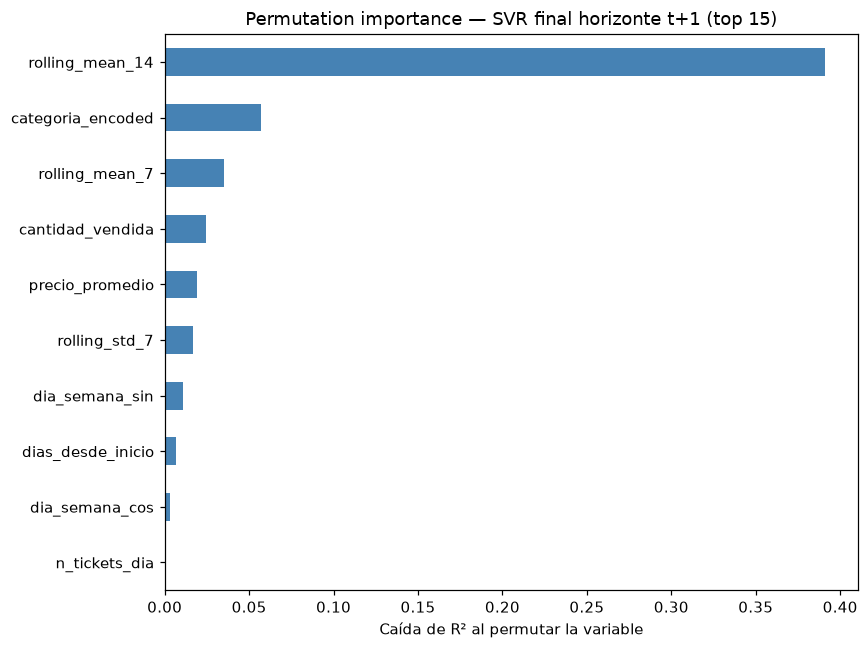

Variables reales nuevas que sobrevivieron la selección: ['precio_promedio', 'n_tickets_dia']
Variables descartadas por falta de señal real: ['hora_promedio_venta', 'es_fecha_especial', 'mes', 'mes_cos', 'mes_sin', 'es_feriado', 'temporada_seca', 'rolling_std_14', 'lag_2', 'lag_14', 'lag_7', 'dia_semana', 'es_weekend', 'lag_1']


In [9]:
perm = permutation_importance(
    svr_models[1], splits[1]["X_test"], splits[1]["y_test"],
    n_repeats=20, random_state=RNG, n_jobs=1,
)
importancia = (
    pd.Series(perm.importances_mean, index=FEATURE_COLS_FINAL)
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(8, 6))
importancia.head(15).iloc[::-1].plot.barh(ax=ax, color="steelblue")
ax.set_title("Permutation importance — SVR final horizonte t+1 (top 15)")
ax.set_xlabel("Caída de R² al permutar la variable")
plt.tight_layout(); plt.show()

nuevas_reales = [c for c in ["precio_promedio", "n_tickets_dia", "hora_promedio_venta"] if c in FEATURE_COLS_FINAL]
print("Variables reales nuevas que sobrevivieron la selección:", nuevas_reales)
print("Variables descartadas por falta de señal real:", descartadas)

## 10. Persistencia de artefactos

In [10]:
for h in HORIZONTES:
    joblib.dump(svr_models[h], MODELS_DIR / f"svr_h{h}.joblib")
joblib.dump(svc_alerta, MODELS_DIR / "svc_alerta.joblib")
joblib.dump(isolation_forest, MODELS_DIR / "isolation_forest.joblib")

with open(MODELS_DIR / "residuales.json", "w") as f:
    json.dump({str(h): residuales[h] for h in HORIZONTES}, f, indent=2)

metadata = {
    "fuente_datos": "ventas.csv real (El Café que te Conté), 2026-04-01 a 2026-07-31",
    "feature_cols_candidatas": FEATURE_COLS,
    "feature_cols_svr": FEATURE_COLS_FINAL,
    "feature_cols_svc_iso": FEATURE_COLS,
    "features_descartadas_svr": descartadas,
    "horizontes": list(HORIZONTES),
    "mejores_hiperparametros": {str(h): svr_best_params[h] for h in HORIZONTES},
    "metricas": {str(h): metricas_por_horizonte[h] for h in HORIZONTES},
    "svc_alerta": {"roc_auc_test": round(float(auc), 4)},
    "isolation_forest": {"contamination": 0.05, "n_anomalias_test": n_anomalias},
    "contexto_historico_no_comparable": {
        "practica_2_sintetico": contexto_p2,
        "informe_svm_sintetico": contexto_informe,
        "nota": "Dataset distinto (sintético, 10 productos electrónicos) — no comparable numéricamente con este modelo (real, 33 productos de cafetería).",
    },
    "importancia_variables_finales": importancia.round(4).to_dict(),
}
with open(MODELS_DIR / "metadata.json", "w") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

print("Artefactos guardados en models/:")
for p in sorted(MODELS_DIR.glob("*")):
    print(" ", p.name)

Artefactos guardados en models/:
  isolation_forest.joblib
  metadata.json
  residuales.json
  svc_alerta.joblib
  svr_h1.joblib
  svr_h1.onnx
  svr_h3.joblib
  svr_h3.onnx
  svr_h7.joblib
  svr_h7.onnx


## Conclusiones

- Primera corrida del pipeline sobre **datos reales** de El Café que te Conté: la
  misma metodología (selección de features + SVR multi-horizonte + intervalos +
  alerta + anomalías) validada con datos sintéticos ahora corre sobre ventas reales
  de 33 productos.
- La selección de features descartó las que no aportan señal real, incluyendo
  posiblemente alguna de las 3 variables reales nuevas (`precio_promedio`,
  `n_tickets_dia`, `hora_promedio_venta`) si no mostraron señal suficiente en este
  primer corte de datos.
- Todos los artefactos quedan en `models/`, listos para que el notebook 3 y la API
  los sirvan sin reentrenar.